# Single Image Processing from a LIF Container

This notebook processes 3D plant root images from LIF containers with the following steps:

1. Predicts 3D nuclei labels using CellposeSAM/pyclesperanto, including anisotropy correction and volume filtering.

All processing steps are visualized in Napari and results are saved to appropriate output folders.

Image Outputs are written to `RAW_DATA_DIRECTORY/<lif_container_id>/`.

### Environment setup
This cell sets up imports and makes sure the src folder is available in Python path.

Input needed from researcher: run this as-is unless your project folder layout is different.

In [1]:
import sys
from pathlib import Path

cwd = Path.cwd().resolve()
src_dir = cwd / "src" if (cwd / "src").exists() else cwd.parent / "src"
if str(src_dir) not in sys.path:
    sys.path.insert(0, str(src_dir))

from utils.io import (
    list_containers,
    explore_lif_container,
    load_lif_image,
    calculate_rescale_factor,
    ensure_output_dir,
    load_precomputed_results_if_available,
)
from utils.segmentation import (
    predict_nuclei_labels_cp,
    predict_nuclei_labels_vo
)

from utils.feature_extraction import extract_nuclei_features_per_marker

from utils.data_viz import (
    map_df_column_to_labels,
    plot_prop_to_3d_centroids
)

import tifffile
import napari



Welcome to CellposeSAM, cellpose v
cellpose version: 	4.0.6 
platform:       	win32 
python version: 	3.10.20 
torch version:  	2.5.0! The neural network component of
CPSAM is much larger than in previous versions and CPU excution is slow. 
We encourage users to use GPU/MPS if available. 


creating new log file
2026-08-04 11:30:15,262 [INFO] WRITING LOG OUTPUT TO C:\Users\adiez_cmic\.cellpose\run.log
2026-08-04 11:30:15,262 [INFO] 
cellpose version: 	4.0.6 
platform:       	win32 
python version: 	3.10.20 
torch version:  	2.5.0


### Configure experiment inputs
Set core paths and model choices used in the workflow.

Input needed from researcher: update RAW_DATA_DIRECTORY, MODEL_DIR, MIN_MAX_NUCLEI_VOLUME, channel indices, marker definitions, and index for image and container from your experiment.

In [2]:
# Copy the path where your .lif containers are stored, you can use absolute or relative paths to point at other disk locations
RAW_DATA_DIRECTORY = r"Z:\margrethe.c.stahl\Ki-67-proliferation"

# Channel index used for CellposeSAM-based 3D nuclei segmentation
NUCLEI_CHANNEL = 0

# Nuclei segmentation method ("cellpose", "voronoi-otsu")
NUCLEI_LABELING = "voronoi-otsu"

# Tunable Voronoi-Otsu parameters, applies if choosing "voronoi-otsu" above
SPOT_SIGMA = 2      # larger -> fewer separated detected spots
OUTLINE_SIGMA = 2   # larger -> smoother object outlines

# Minimum and maximum nuclei label volume to use for filtering predicted nuclei labels.
# Use a (min, max) voxel-count tuple, or None to skip volume filtering.
MIN_MAX_NUCLEI_VOLUME = None #(500, 6500) seems safe after exploring the volume distribution

# Marker information
MARKERS = (("DAPI", 0), ("F-Actin", 1), ("ki67", 2), ("brightfield", 3))

# Mark the position of the .lif container you want to open in your raw data folder (first = 0, second = 1, third = 2)
LIF_CONTAINER_INDEX = 0 

# Mark the position of the image inside the .lif container you want to open (first = 0, second = 1, third = 2)
LIF_IMAGE_INDEX = 0

### Discover LIF containers
This cell scans the raw data directory and lists available .lif containers.

Input needed from researcher: confirm the directory contains the expected files.

In [3]:
# Iterate through the .lif container files in the directory
lif_containers = list_containers(RAW_DATA_DIRECTORY, file_format="lif")

if not lif_containers:
    raise FileNotFoundError(
        f"No .lif containers found in '{RAW_DATA_DIRECTORY}'. "
        "Check RAW_DATA_DIRECTORY and file extension."
    )

if not 0 <= LIF_CONTAINER_INDEX < len(lif_containers):
    raise IndexError(
        f"LIF_CONTAINER_INDEX={LIF_CONTAINER_INDEX} is out of range. "
        f"Valid range is 0..{len(lif_containers)-1}."
    )

lif_containers

['Z:\\margrethe.c.stahl\\Ki-67-proliferation\\A549-perfusion-day3andday14.lif',
 'Z:\\margrethe.c.stahl\\Ki-67-proliferation\\A549-perfusion-day7-26.11.25.lif',
 'Z:\\margrethe.c.stahl\\Ki-67-proliferation\\A549-static-day3andday14-11.11.25.lif',
 'Z:\\margrethe.c.stahl\\Ki-67-proliferation\\A549-static-day7-26.11.25.lif']

### Select one container and image
Choose the container and image index to analyze, then load metadata and image data.

Input needed from researcher: set LIF_CONTAINER_INDEX and LIF_IMAGE_INDEX to the sample you want to inspect in the cells above.

In [4]:
# Explore different .lif files (0 defines the first file in the directory)
lif_path = lif_containers[LIF_CONTAINER_INDEX]

# Explore the contents of a single .lif container
nr_imgs, lif_container_id = explore_lif_container(file_path=lif_path, display=True)

# Load a single image from a .lif container
lif_image, lif_image_name, xml_metadata = load_lif_image(file_path=lif_path, image_index=LIF_IMAGE_INDEX)


Image name: d3-E-5x-zoom1-325um, Dimensions: ('Z', 'C', 'Y', 'X'), Array Shape: (20, 4, 1024, 1024)
Image name: d3-E-10x-zoom1-279um, Dimensions: ('Z', 'C', 'Y', 'X'), Array Shape: (117, 4, 1024, 1024)
Image name: d3-E-10x-zoo,1-279um, Dimensions: ('Z', 'C', 'Y', 'X'), Array Shape: (117, 4, 1024, 1024)
Image name: d3-E-10x-zoom1.5-315um, Dimensions: ('Z', 'C', 'Y', 'X'), Array Shape: (132, 4, 1024, 1024)
Image name: Series005, Dimensions: ('Z', 'C', 'Y', 'X'), Array Shape: (4, 4, 1024, 1024)
Image name: d3-5x, Dimensions: ('Z', 'C', 'Y', 'X'), Array Shape: (13, 4, 1024, 1024)
Image name: Series007, Dimensions: ('Z', 'C', 'Y', 'X'), Array Shape: (43, 4, 1024, 1024)
Image name: d3-B-5x-enkule, Dimensions: ('Z', 'C', 'Y', 'X'), Array Shape: (15, 4, 1024, 1024)
Image name: D14-E-10x-zoom1, Dimensions: ('Z', 'C', 'Y', 'X'), Array Shape: (107, 4, 1024, 1024)
Image name: D14-E-10x-zoom1.5, Dimensions: ('Z', 'C', 'Y', 'X'), Array Shape: (102, 4, 1024, 1024)
Image name: D14-E-10x-zoom1.5-2, Dim

### Display input channels in Napari
This opens a 3D Napari view of all channels to verify image quality and channel order.

Input needed from researcher: visually confirm that channels and marker names match expectations.

In [5]:
# Initialize Napari Viewer and display all input channels
viewer = napari.Viewer(ndisplay=3)
viewer.add_image(lif_image, 
                channel_axis=0,
                colormap=['cyan', 'yellow', 'magenta', 'grey'],
                name=[tuple[0] for tuple in MARKERS]
                )

[<Image layer 'DAPI' at 0x2047a9cfa90>,
 <Image layer 'F-Actin' at 0x2042f8fae30>,
 <Image layer 'ki67' at 0x2042fa4fe50>,
 <Image layer 'brightfield' at 0x2042fa648e0>]

### Predict or load nuclei labels (CellposeSAM or Voronoi-Otsu)
This step checks if nuclei label masks already exist for the selected image. If so, they are loaded and displayed in Napari. Otherwise, new nuclei labels are predicted—either with CellposeSAM (default) or Voronoi-Otsu—using anisotropy correction.
 
- If CellposeSAM is selected, set and verify Z anisotropy and the DAPI channel.
- If Voronoi-Otsu is used, on top of anisotropy and DAPI channel, adjust `SPOT_SIGMA` (larger = merges nearby nuclei) and `OUTLINE_SIGMA` (controls nucleus boundary smoothness).
The resulting labels are visualized in Napari and saved for future reuse.

In [6]:
# Ensure output directory for this container's nuclei labels
nuclei_labels_dir = ensure_output_dir(RAW_DATA_DIRECTORY, lif_container_id, results_type="nuclei_labels")
print(f"Nuclei labels directory: {nuclei_labels_dir}")

# Calculate anisotropy CellposeSAM parameter to rescale across the Z-axis (ratio of Z-resolution to XY-resolution)
rescale_factor = calculate_rescale_factor(xml_metadata, display=True)

# Load precomputed labels when available; otherwise predict and store them
nuclei_labels = load_precomputed_results_if_available(nuclei_labels_dir, lif_image_name, results_type="nuclei_labels")

if nuclei_labels is not None:
    print(f"Predictions already calculated for: {lif_image_name} ...loading")
    # Add the prediction to the napari viewer
    viewer.add_labels(nuclei_labels)
    
else:
    if NUCLEI_LABELING == "voronoi-otsu":
        # Predict nuclei labels using Voronoi-Otsu (pyclesperanto) using anisotropy correction
        nuclei_labels = predict_nuclei_labels_vo(lif_image, rescale_factor, NUCLEI_CHANNEL, MIN_MAX_NUCLEI_VOLUME, SPOT_SIGMA, OUTLINE_SIGMA, visualize=True)
    else:
        print("Defaulting to Cellpose for nuclei label prediction")
        # Predict nuclei labels using CellposeSAM using anisotropy correction
        nuclei_labels = predict_nuclei_labels_cp(lif_image, rescale_factor, NUCLEI_CHANNEL, MIN_MAX_NUCLEI_VOLUME, visualize=True)

    # Create path for nuclei labels (used only when saving a newly computed prediction)
    nuclei_labels_path = nuclei_labels_dir / f"{lif_image_name}_nuclei_labels.tif"
    # Save the prediction
    tifffile.imwrite(nuclei_labels_path, nuclei_labels)



Nuclei labels directory: Z:\margrethe.c.stahl\Ki-67-proliferation\nuclei_labels\A549-perfusion-day3andday14
x_um: 2.2705078125, y_um: 2.2705078125, z_um: 17.133915789473683
Rescale factor: 7.54629237351443
Predictions already calculated for: d3-E-5x-zoom1-325um ...loading


### Extract nuclei features
Build image descriptors and compute per-nucleus morphological and intensity features.

Input needed from researcher: confirm marker/channel mapping reflects your biological labels.

In [7]:
# Create a dictionary containing all image descriptors
descriptor_dict = {
            "lif_container_id": lif_container_id,
            "lif_image_name": lif_image_name,
            }

# Extract morphological and intensity features per marker
props_df = extract_nuclei_features_per_marker(nuclei_labels, lif_image, MARKERS, descriptor_dict)

### Visualize extracted features in Napari
Render normalized volume per nucleus for exploratory interpretation.

Input needed from researcher: verify normalization and inspect outliers before analysis.

In [8]:
# Visualize nuclei volumes
fret_img = map_df_column_to_labels(
    nuclei_labels,
    props_df,
    value_column="area",
    colormap="inferno",
    visualize=True
)

In [9]:
# Visualize ki67 mean intensity
fret_img = map_df_column_to_labels(
    nuclei_labels,
    props_df,
    value_column="ki67_mean_int",
    colormap="inferno",
    visualize=True
)

### Matplotlib visualization

Besides Napari you can use Matplotlib for visualizing your results in a static graph

C:\Users\adiez_cmic\github_repos\margrecs_alginate\src\utils\data_viz.py:238: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


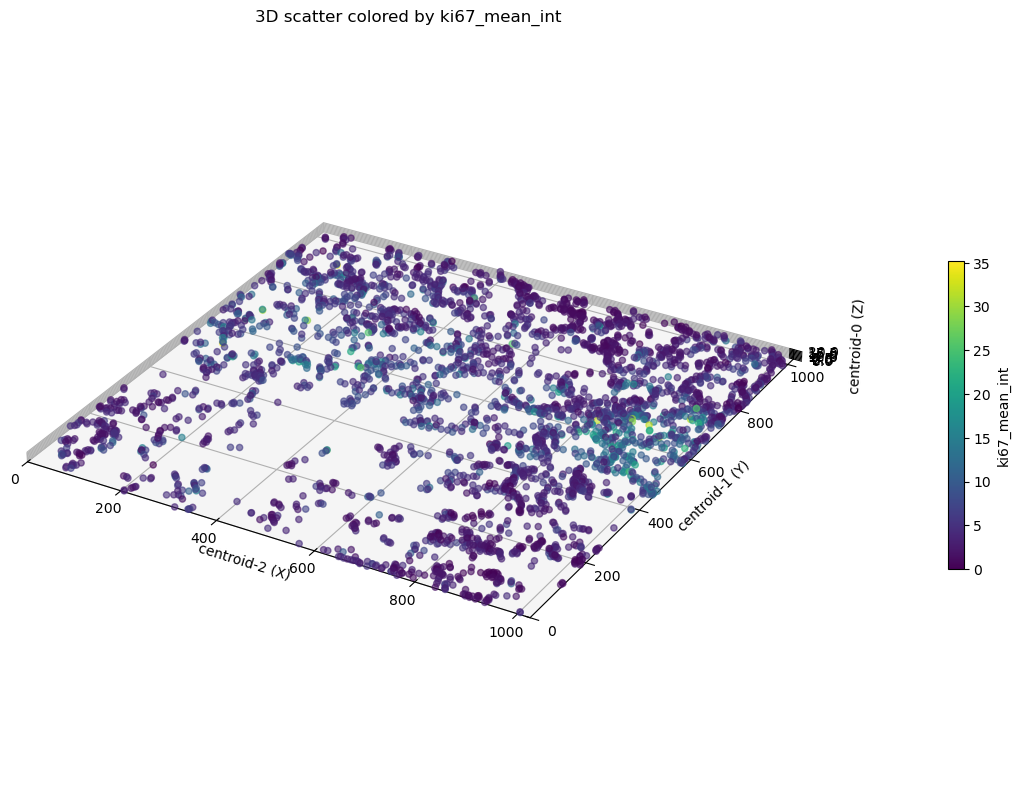

In [10]:
plot_prop_to_3d_centroids(
    props_df,
    value_column="ki67_mean_int",
    colormap="viridis",
    nuclei_labels_shape=nuclei_labels.shape,
    fig_title=None,
    ax_labels=None,
    colormap_vmin=None,
    colormap_vmax=None,
    save_fig=False,
    fig_filename=None,
    fig_savepath=None,
    visualize=True
)

In [11]:
import plotly.express as px

fig = px.histogram(
    props_df,
    x="area",
    nbins=100,
    title="Histogram of Nuclei Area",
    labels={"area": "Nucleus Area", "count": "Count"},
    opacity=0.7
)
fig.update_traces(marker_color="steelblue", marker_line_color="black", marker_line_width=1)
fig.update_layout(bargap=0.05)
fig.show()